# Pokédex intelligent — Niveau 1 : données tabulaires

Objectifs (consignes) :
1. **Clustering** : identifier des groupes dans les statistiques et les interpréter.
2. **Classification** à partir des 6 statistiques de base :
   - le Pokémon est-il **légendaire** ? (on veut une **probabilité**) ;
   - quel est son **type** (on prédit le `Type 1`).
3. **Comparer rigoureusement plusieurs modèles** avec des métriques adaptées et justifier le choix.

Tout le code « métier » est dans `pokedex_ml.py` ; ce notebook l'appelle et commente les résultats.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

import pokedex_ml as pml

warnings.filterwarnings("ignore", category=UserWarning)  # avertissement "classe Flying < 5 exemples"
pd.set_option("display.precision", 3)
df = pml.charger_donnees()
df.head()

,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary,Total
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False,318
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False,405
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False,525
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False,625
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False,309


## 1. Exploration rapide

In [2]:
print(df.shape[0], "Pokémon")
print("Légendaires :", df["Legendary"].sum(), f"({df['Legendary'].mean():.1%})")
df[pml.STATS + ["Total"]].describe()

800 Pokémon
Légendaires : 65 (8.1%)


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Total
count,800.000,800.000,800.000,800.000,800.000,800.000,800.000
mean,69.259,79.001,73.843,72.820,71.903,68.278,435.103
std,25.535,32.457,31.184,32.722,27.829,29.060,119.963
min,1.000,5.000,5.000,10.000,20.000,5.000,180.000
25%,50.000,55.000,50.000,49.750,50.000,45.000,330.000
50%,65.000,75.000,70.000,65.000,70.000,65.000,450.000
75%,80.000,100.000,90.000,95.000,90.000,90.000,515.000
max,255.000,190.000,230.000,194.000,230.000,180.000,780.000


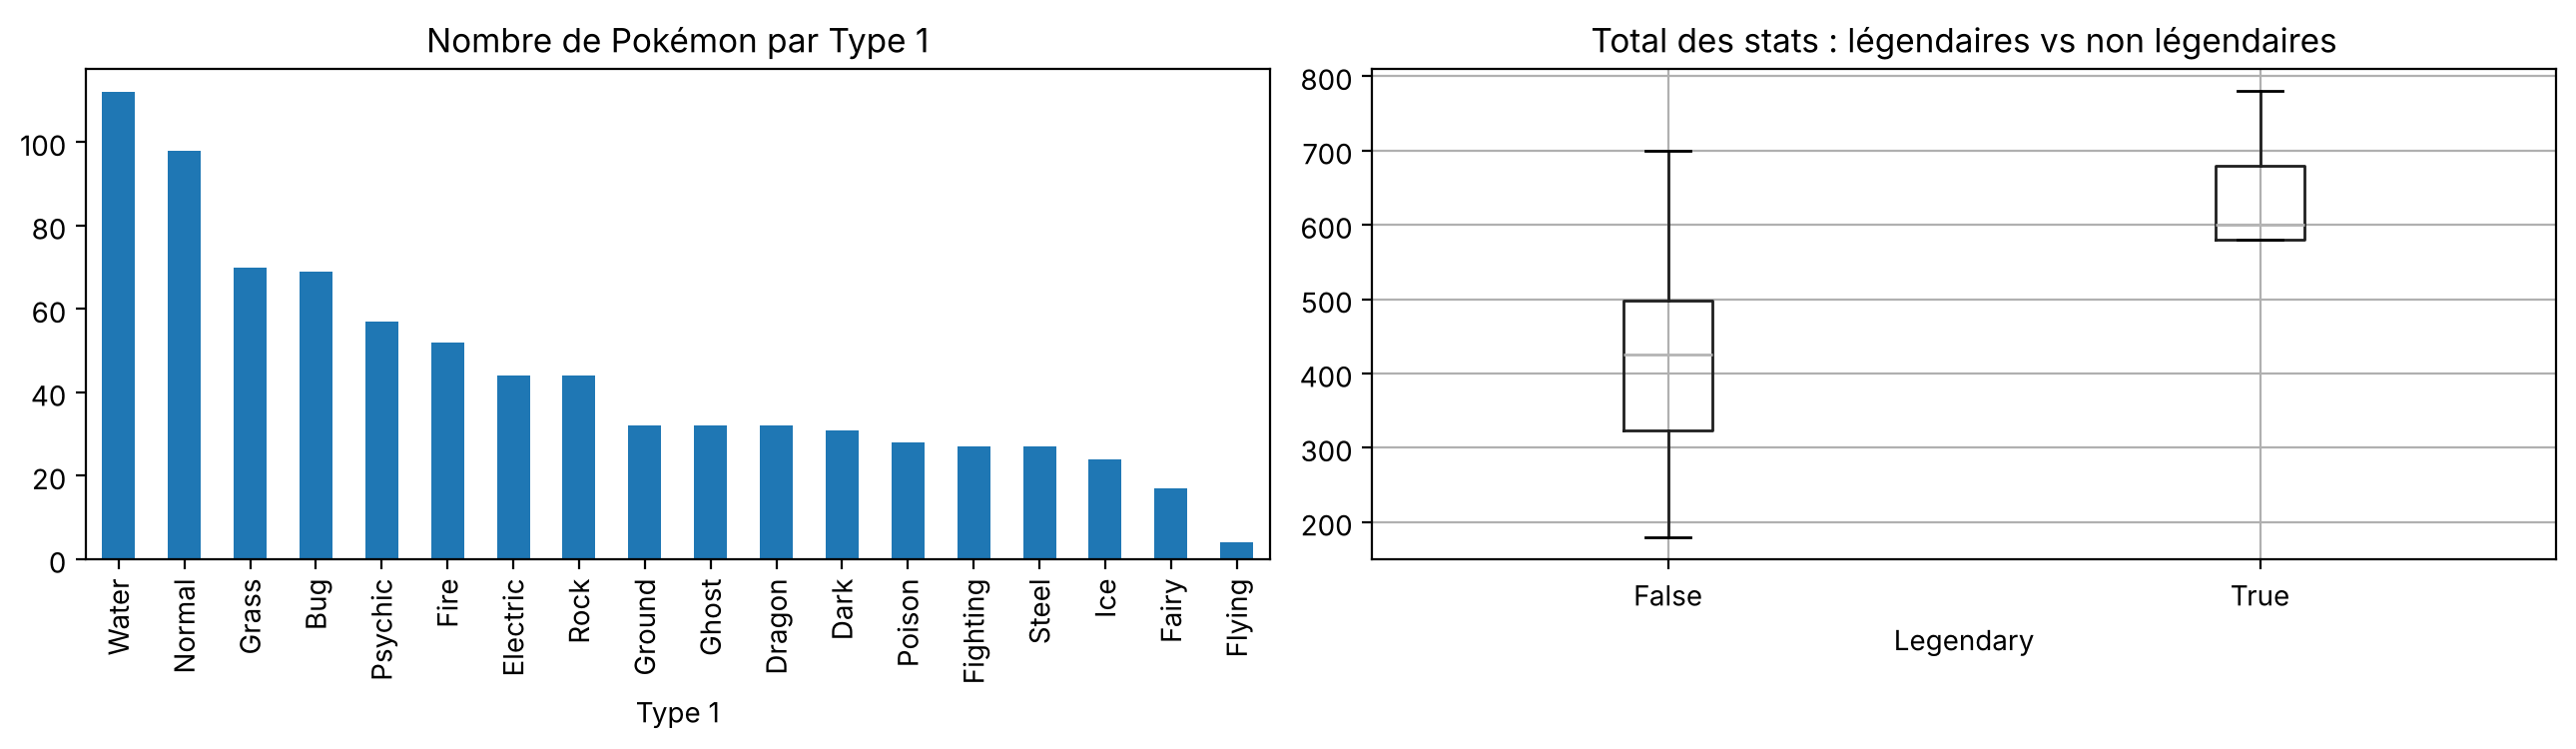

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["Type 1"].value_counts().plot.bar(ax=axes[0], title="Nombre de Pokémon par Type 1")
df.boxplot(column="Total", by="Legendary", ax=axes[1])
axes[1].set_title("Total des stats : légendaires vs non légendaires"); fig.suptitle("")
plt.tight_layout(); plt.show()

**À retenir** : les deux problèmes sont **déséquilibrés** (8 % de légendaires ; 112 « Water » contre
4 « Flying »). L'accuracy seule sera donc trompeuse : on utilisera des métriques adaptées.
Les légendaires ont un Total nettement plus élevé, on s'attend donc à bien les détecter.

## 2. Clustering (K-Means)

Les stats sont **standardisées** (moyenne 0, écart-type 1) avant le K-Means, sinon la distance
serait dominée par les stats à grandes valeurs. Choix du nombre de groupes `k` :
méthode du **coude** (inertie) et **silhouette score**.

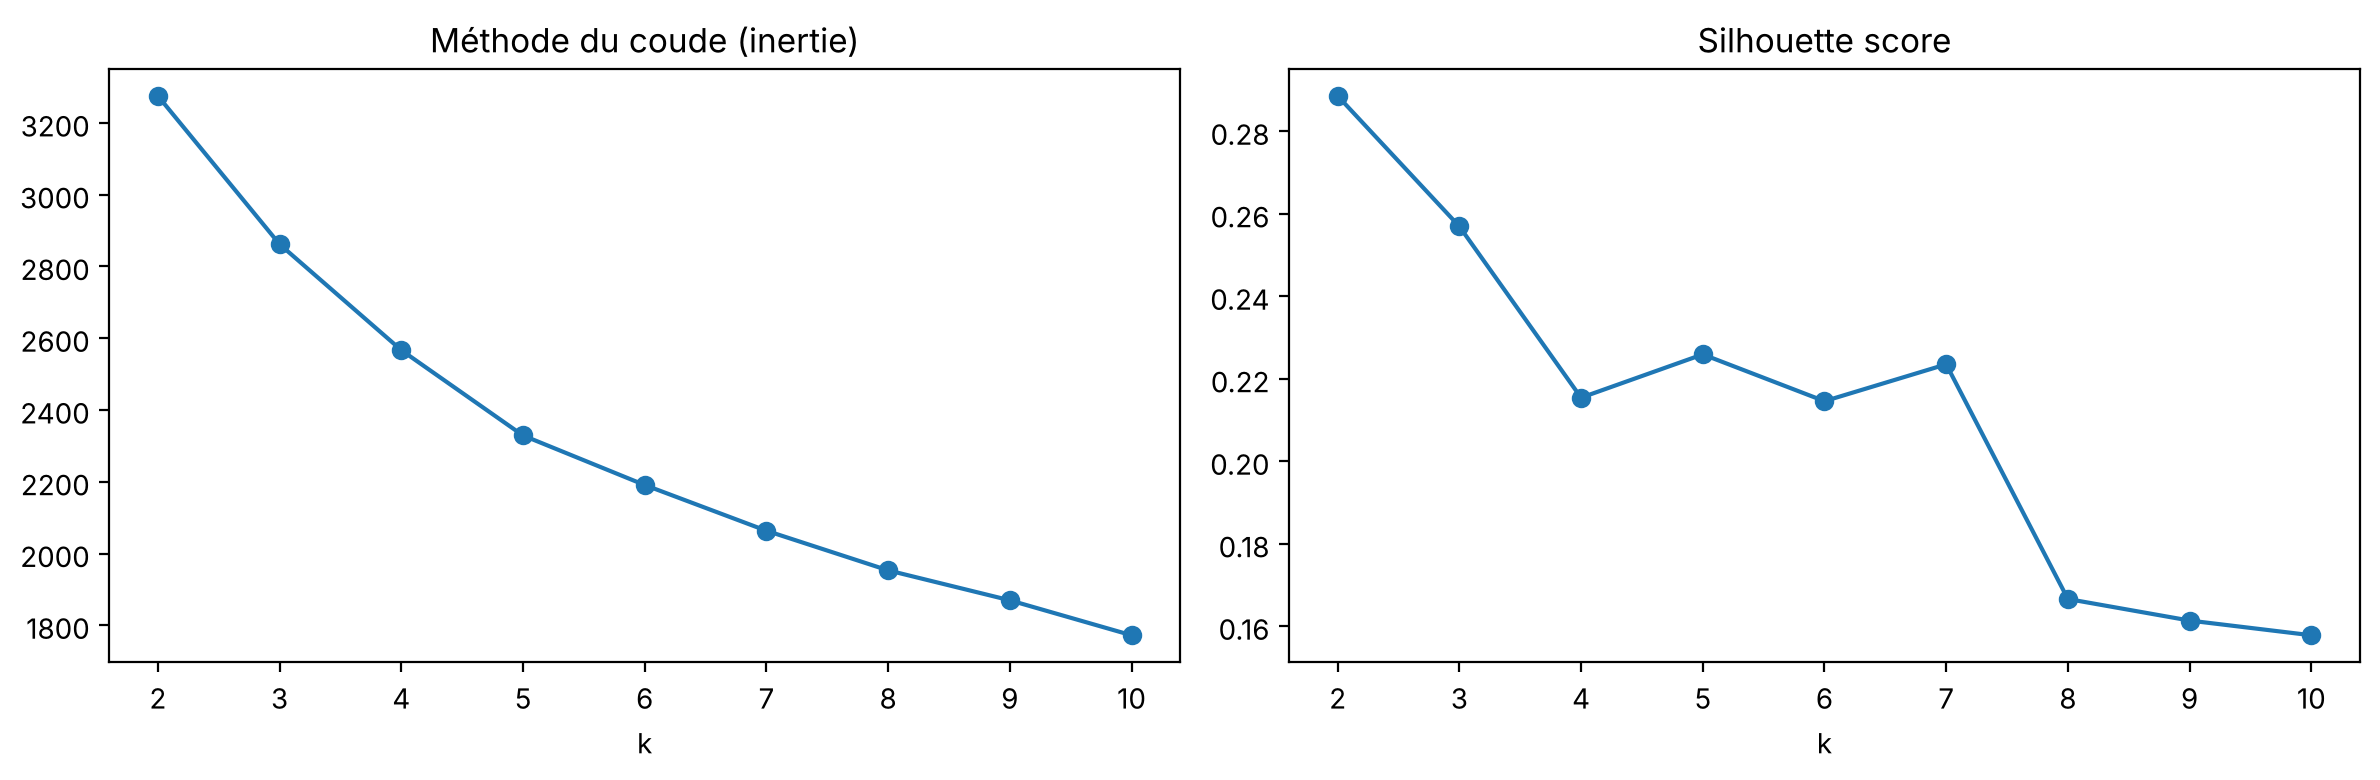

,inertie,silhouette
k,,
2,3275.381,0.289
3,2862.058,0.257
4,2566.779,0.215
5,2328.942,0.226
6,2190.852,0.215
7,2063.423,0.223
8,1953.016,0.167
9,1869.563,0.161
10,1772.129,0.158


In [4]:
choix_k = pml.scores_choix_k(df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
choix_k["inertie"].plot(marker="o", ax=axes[0], title="Méthode du coude (inertie)")
choix_k["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette score")
plt.tight_layout(); plt.show()
choix_k

**Choix de k = 5** (constante `NB_CLUSTERS` dans pokedex_ml.py) : le silhouette est maximal pour k = 2, mais ce découpage est trivial
(« faibles » / « forts »). Le coude n'est pas net. k = 5 forme un petit pic local du silhouette
(meilleur que k = 3, 4 et 6) et donne des groupes **interprétables**. Remarque honnête : un silhouette autour de 0,2 signifie que les groupes se
chevauchent ; les stats des Pokémon forment plutôt un continuum que des groupes bien séparés.

In [5]:
clustering = pml.Clustering(df)
clustering.description

,Interprétation,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Total,Effectif,Part_legendaires
Groupe,,,,,,,,,,
0,Faibles (souvent non évolués),50.31,54.05,51.68,48.16,49.06,49.21,302.46,281,0.00
1,Intermédiaires – défensifs,64.59,86.01,123.45,68.22,92.10,53.05,487.42,103,0.06
2,Surpuissants (profil légendaire) – offensifs,89.55,118.41,92.81,121.19,98.75,98.42,619.12,118,0.49
3,Intermédiaires – endurants (PV élevés),102.28,90.51,76.14,78.44,79.22,56.35,482.95,113,0.00
4,Intermédiaires – rapides / offensifs,67.53,80.83,66.39,78.55,73.76,93.79,460.85,185,0.01


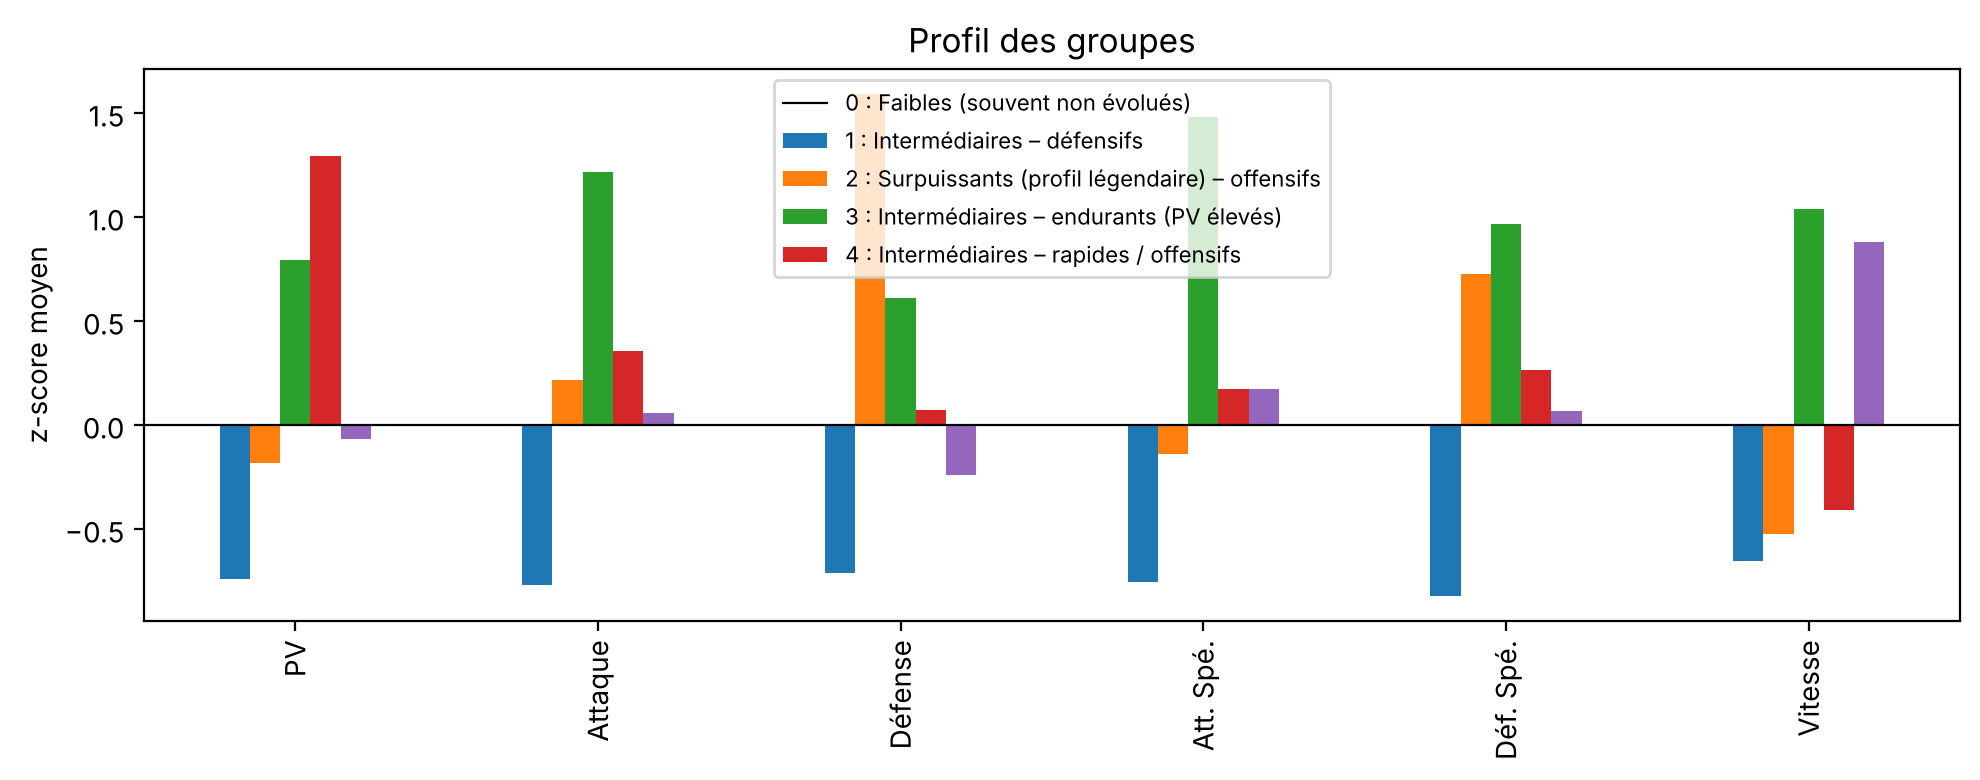

Groupe 0 (Faibles (souvent non évolués)) — exemples : Snorunt, Ditto, Inkay
Groupe 1 (Intermédiaires – défensifs) — exemples : Crustle, Marowak, Mega Mawile
Groupe 2 (Surpuissants (profil légendaire) – offensifs) — exemples : Hydreigon, Landorus Incarnate Forme, Genesect
Groupe 3 (Intermédiaires – endurants (PV élevés)) — exemples : Whiscash, Swalot, Seismitoad
Groupe 4 (Intermédiaires – rapides / offensifs) — exemples : Golbat, Girafarig, Xatu


In [6]:
# Profil de chaque groupe en écart-types par rapport à la moyenne générale
ax = clustering.profils_z.rename(columns=pml.STATS_FR).T.plot.bar(figsize=(10, 4))
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("z-score moyen")
ax.legend([f"{g} : {n}" for g, n in clustering.noms.items()], fontsize=8)
plt.title("Profil des groupes"); plt.tight_layout(); plt.show()
for g, ex in clustering.exemples.items():
    print(f"Groupe {g} ({clustering.noms[g]}) — exemples : {', '.join(ex)}")

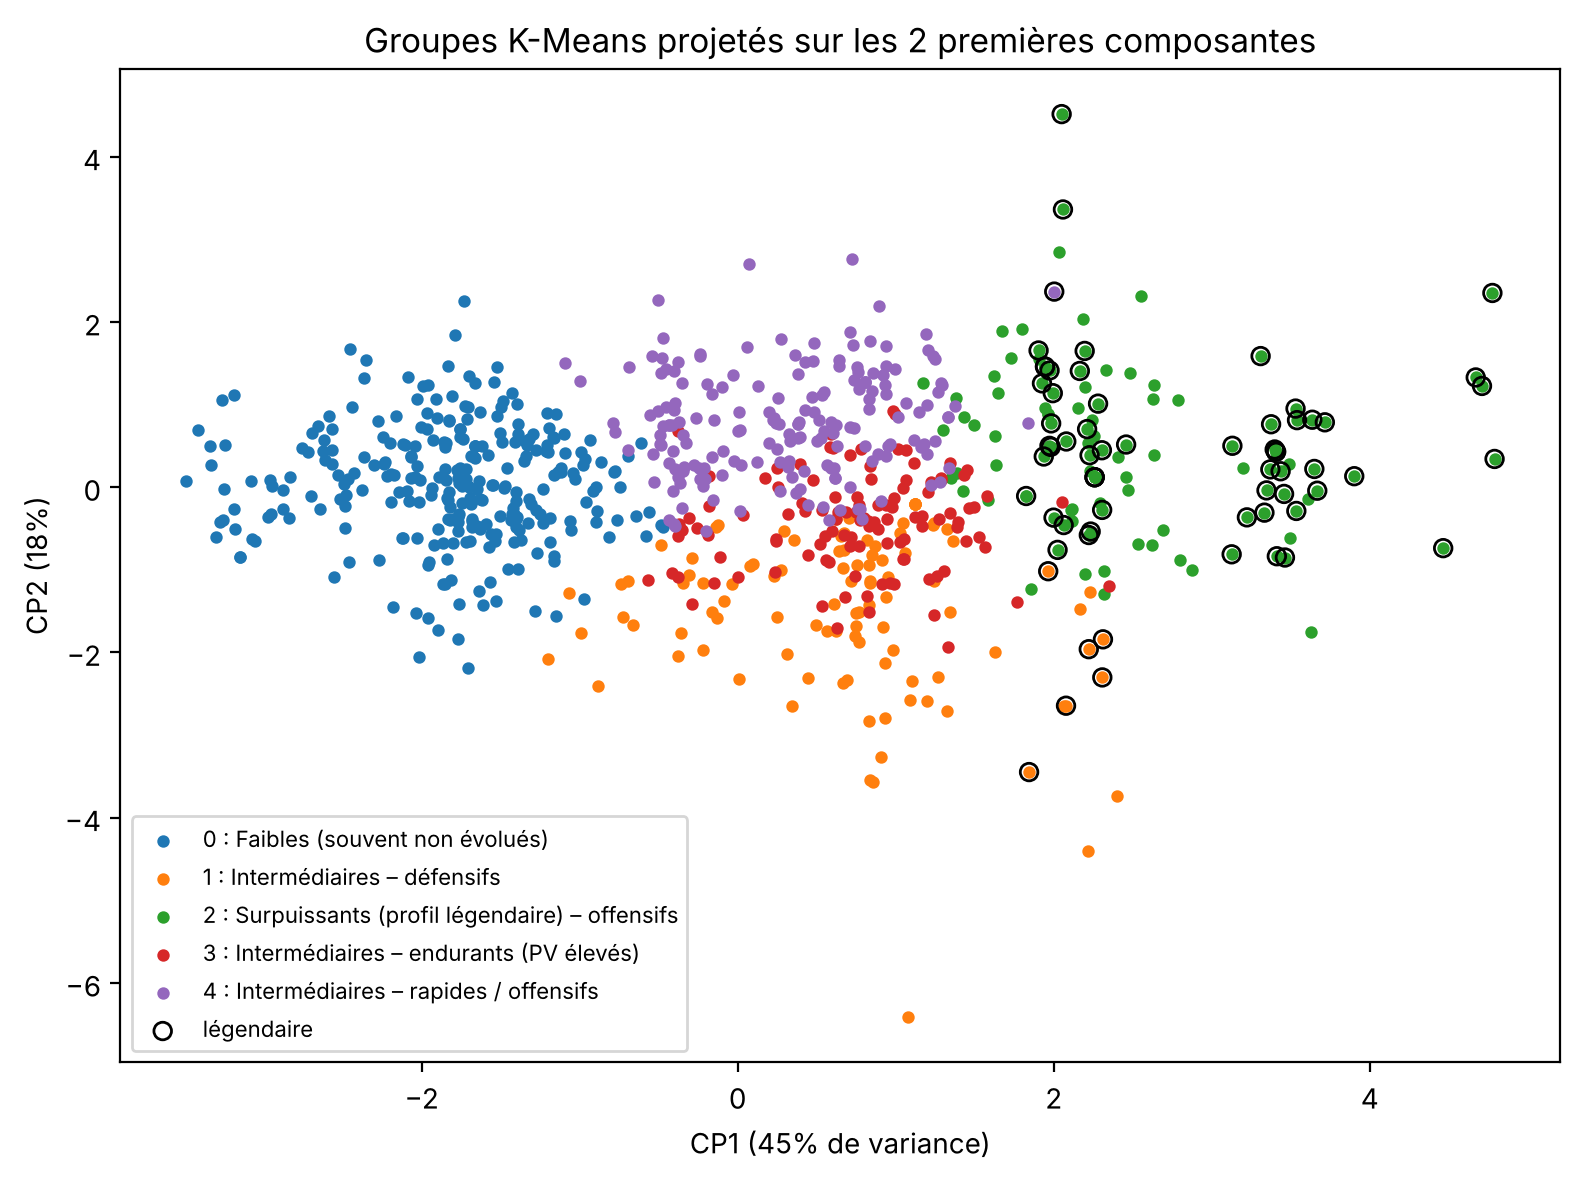

In [7]:
# Visualisation 2D par ACP (analyse en composantes principales)
coords, variance = clustering.projection_2d(df)
plt.figure(figsize=(8, 6))
for g in range(clustering.k):
    m = clustering.labels == g
    plt.scatter(coords[m, 0], coords[m, 1], s=12, label=f"{g} : {clustering.noms[g]}")
leg = df["Legendary"].values
plt.scatter(coords[leg, 0], coords[leg, 1], s=40, facecolors="none", edgecolors="k", label="légendaire")
plt.xlabel(f"CP1 ({variance[0]:.0%} de variance)"); plt.ylabel(f"CP2 ({variance[1]:.0%})")
plt.legend(fontsize=8); plt.title("Groupes K-Means projetés sur les 2 premières composantes")
plt.tight_layout(); plt.show()

**Interprétation** (à vérifier sur la sortie ci-dessus) : un groupe de Pokémon **faibles**
(souvent des formes non évoluées), trois groupes **intermédiaires** qui se distinguent par leur style
(défensifs, endurants avec beaucoup de PV, rapides) et un groupe **surpuissant** qui contient presque tous les
légendaires (et les Méga-évolutions). La 1re composante principale correspond en gros au Total.

## 3. Prédire si un Pokémon est légendaire

Protocole (le même pour les deux problèmes) :
- découpage **80 % entraînement / 20 % test stratifié** (le test n'est utilisé qu'une fois, à la fin) ;
- **validation croisée stratifiée à 5 plis** sur l'entraînement pour comparer les modèles ;
- `class_weight="balanced"` pour compenser le faible nombre de légendaires ;
- un modèle **de référence** (toujours « non légendaire ») pour savoir ce que vaut « ne rien apprendre ».

Critère principal : **PR-AUC** (aire sous la courbe précision-rappel), adaptée quand la classe positive
est rare et qu'on exploite une **probabilité** (ce que l'application affiche).

In [8]:
comparaison_leg = pml.comparer_modeles(df, "Legendary")
comparaison_leg[[c for c in comparaison_leg.columns if "écart" not in c]]

,accuracy,accuracy_equilibree,precision,rappel,f1,roc_auc,pr_auc
Modèle,,,,,,,
Régression logistique,0.928,0.943,0.541,0.962,0.690,0.975,0.770
Forêt aléatoire,0.944,0.830,0.661,0.695,0.668,0.976,0.767
Naïf bayésien gaussien,0.938,0.904,0.598,0.864,0.696,0.961,0.751
SVM (noyau RBF),0.931,0.750,0.597,0.535,0.547,0.970,0.711
k-NN (k=7),0.945,0.752,0.720,0.522,0.596,0.963,0.689
Arbre de décision,0.925,0.828,0.543,0.713,0.609,0.833,0.466
Référence (classe majoritaire),0.919,0.500,0.000,0.000,0.000,0.500,0.081


In [9]:
# Stabilité : écart-type des scores sur les 5 plis
comparaison_leg[[c for c in comparaison_leg.columns if "écart" in c]]

,accuracy (écart-type),accuracy_equilibree (écart-type),precision (écart-type),rappel (écart-type),f1 (écart-type),roc_auc (écart-type),pr_auc (écart-type)
Modèle,,,,,,,
Régression logistique,0.019,0.025,0.075,0.047,0.063,0.011,0.096
Forêt aléatoire,0.015,0.058,0.092,0.122,0.069,0.011,0.094
Naïf bayésien gaussien,0.015,0.031,0.097,0.082,0.035,0.017,0.059
SVM (noyau RBF),0.010,0.072,0.057,0.156,0.092,0.005,0.084
k-NN (k=7),0.014,0.079,0.089,0.160,0.135,0.017,0.087
Arbre de décision,0.018,0.047,0.066,0.104,0.044,0.047,0.064
Référence (classe majoritaire),0.004,0.000,0.000,0.000,0.000,0.000,0.004


Modèle retenu : Régression logistique
accuracy               0.906
accuracy_equilibree    0.914
precision              0.462
rappel                 0.923
f1                     0.615
roc_auc                0.953
pr_auc                 0.612
dtype: float64


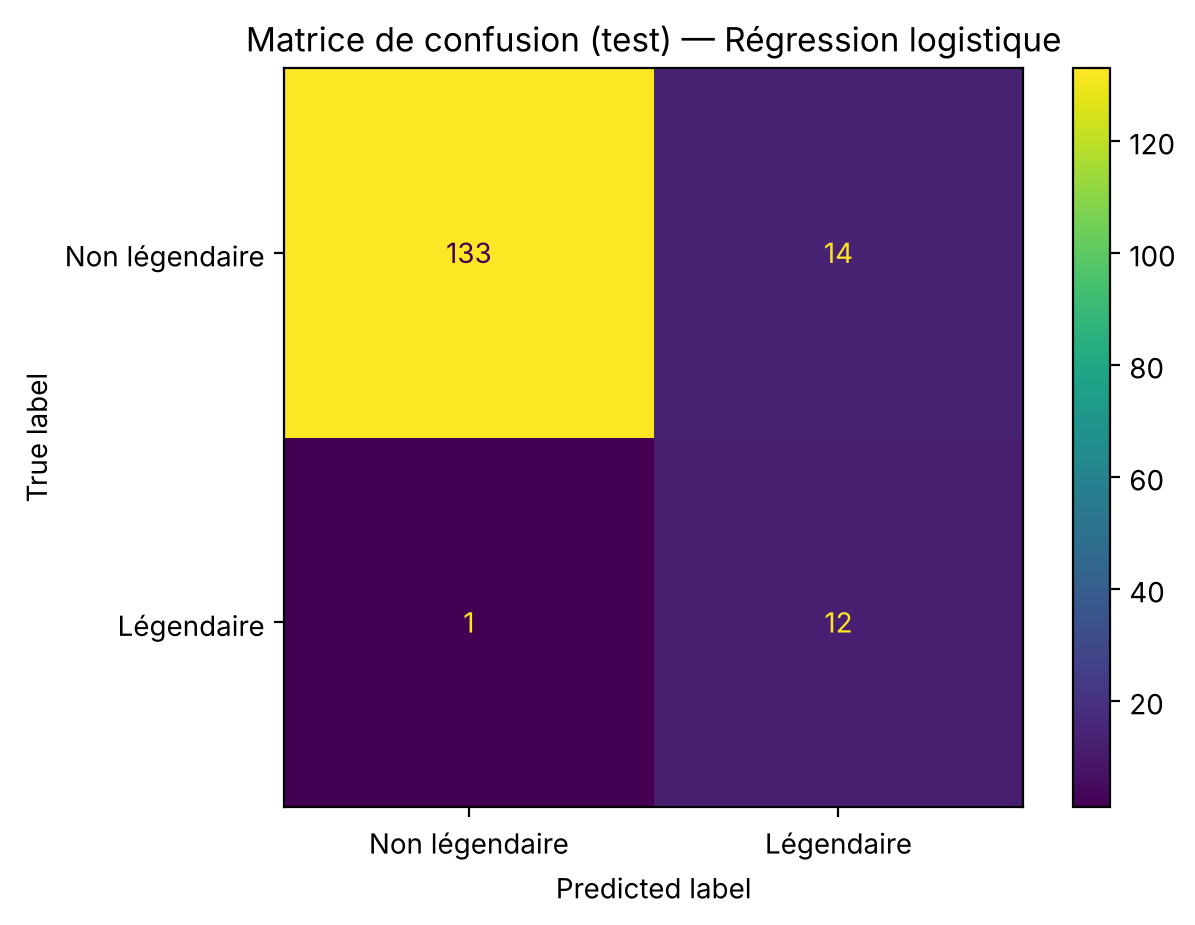

In [10]:
nom_leg = pml.MODELE_RETENU["Legendary"]
scores_leg, y_test, y_pred, modele_leg = pml.evaluer_sur_test(df, "Legendary", nom_leg)
print("Modèle retenu :", nom_leg)
print(pd.Series(scores_leg).round(3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Non légendaire", "Légendaire"])
plt.title(f"Matrice de confusion (test) — {nom_leg}"); plt.show()

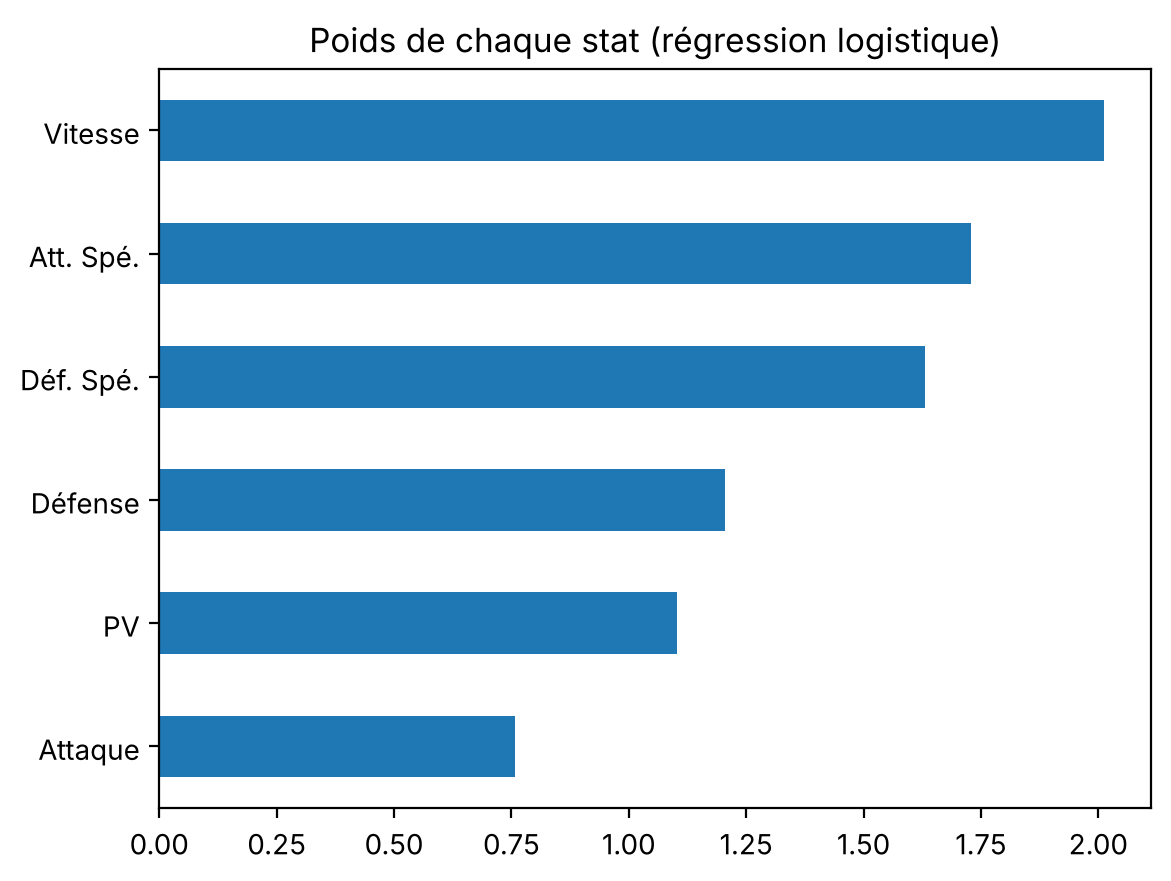

In [11]:
# Interprétation de la régression logistique : poids de chaque stat (stats standardisées)
if nom_leg == "Régression logistique":
    coefs = pd.Series(modele_leg[-1].coef_[0], index=[pml.STATS_FR[s] for s in pml.STATS])
    coefs.sort_values().plot.barh(title="Poids de chaque stat (régression logistique)")
    plt.show()

**Choix** : régression logistique et forêt aléatoire sont à égalité en PR-AUC (≈ 0,77 en validation
croisée). On retient la **régression logistique** : meilleur rappel (elle rate très peu de légendaires),
plus simple, interprétable (un poids par stat), et ses écarts-types montrent qu'elle est stable.

**Limites** :
- `class_weight="balanced"` gonfle les probabilités de la classe rare : la « probabilité d'être
  légendaire » est surtout un **score de confiance**, à ne pas lire comme une fréquence exacte ;
- les **Méga-évolutions** non légendaires ont des stats de légendaire => principaux faux positifs ;
- 65 légendaires seulement : les scores sur le test (13 légendaires) varient beaucoup d'un tirage à l'autre.

## 4. Prédire le type principal (Type 1)

18 classes déséquilibrées. Critère principal : **F1 macro** (chaque type compte autant, même les rares).
On regarde aussi le **top-3 accuracy** : le vrai type est-il parmi les 3 propositions du Pokédex ?

In [12]:
comparaison_type = pml.comparer_modeles(df, "Type 1")
comparaison_type[[c for c in comparaison_type.columns if "écart" not in c]]

,accuracy,accuracy_equilibree,f1_macro,top3_accuracy
Modèle,,,,
Forêt aléatoire,0.222,0.174,0.167,0.467
k-NN (k=7),0.188,0.155,0.142,0.422
Naïf bayésien gaussien,0.172,0.157,0.138,0.419
SVM (noyau RBF),0.241,0.169,0.133,0.517
Régression logistique,0.217,0.151,0.131,0.503
Arbre de décision,0.163,0.113,0.099,0.378
Référence (classe majoritaire),0.141,0.057,0.014,0.350


Modèle retenu : Forêt aléatoire
accuracy               0.288
accuracy_equilibree    0.223
f1_macro               0.219
top3_accuracy          0.500
dtype: float64


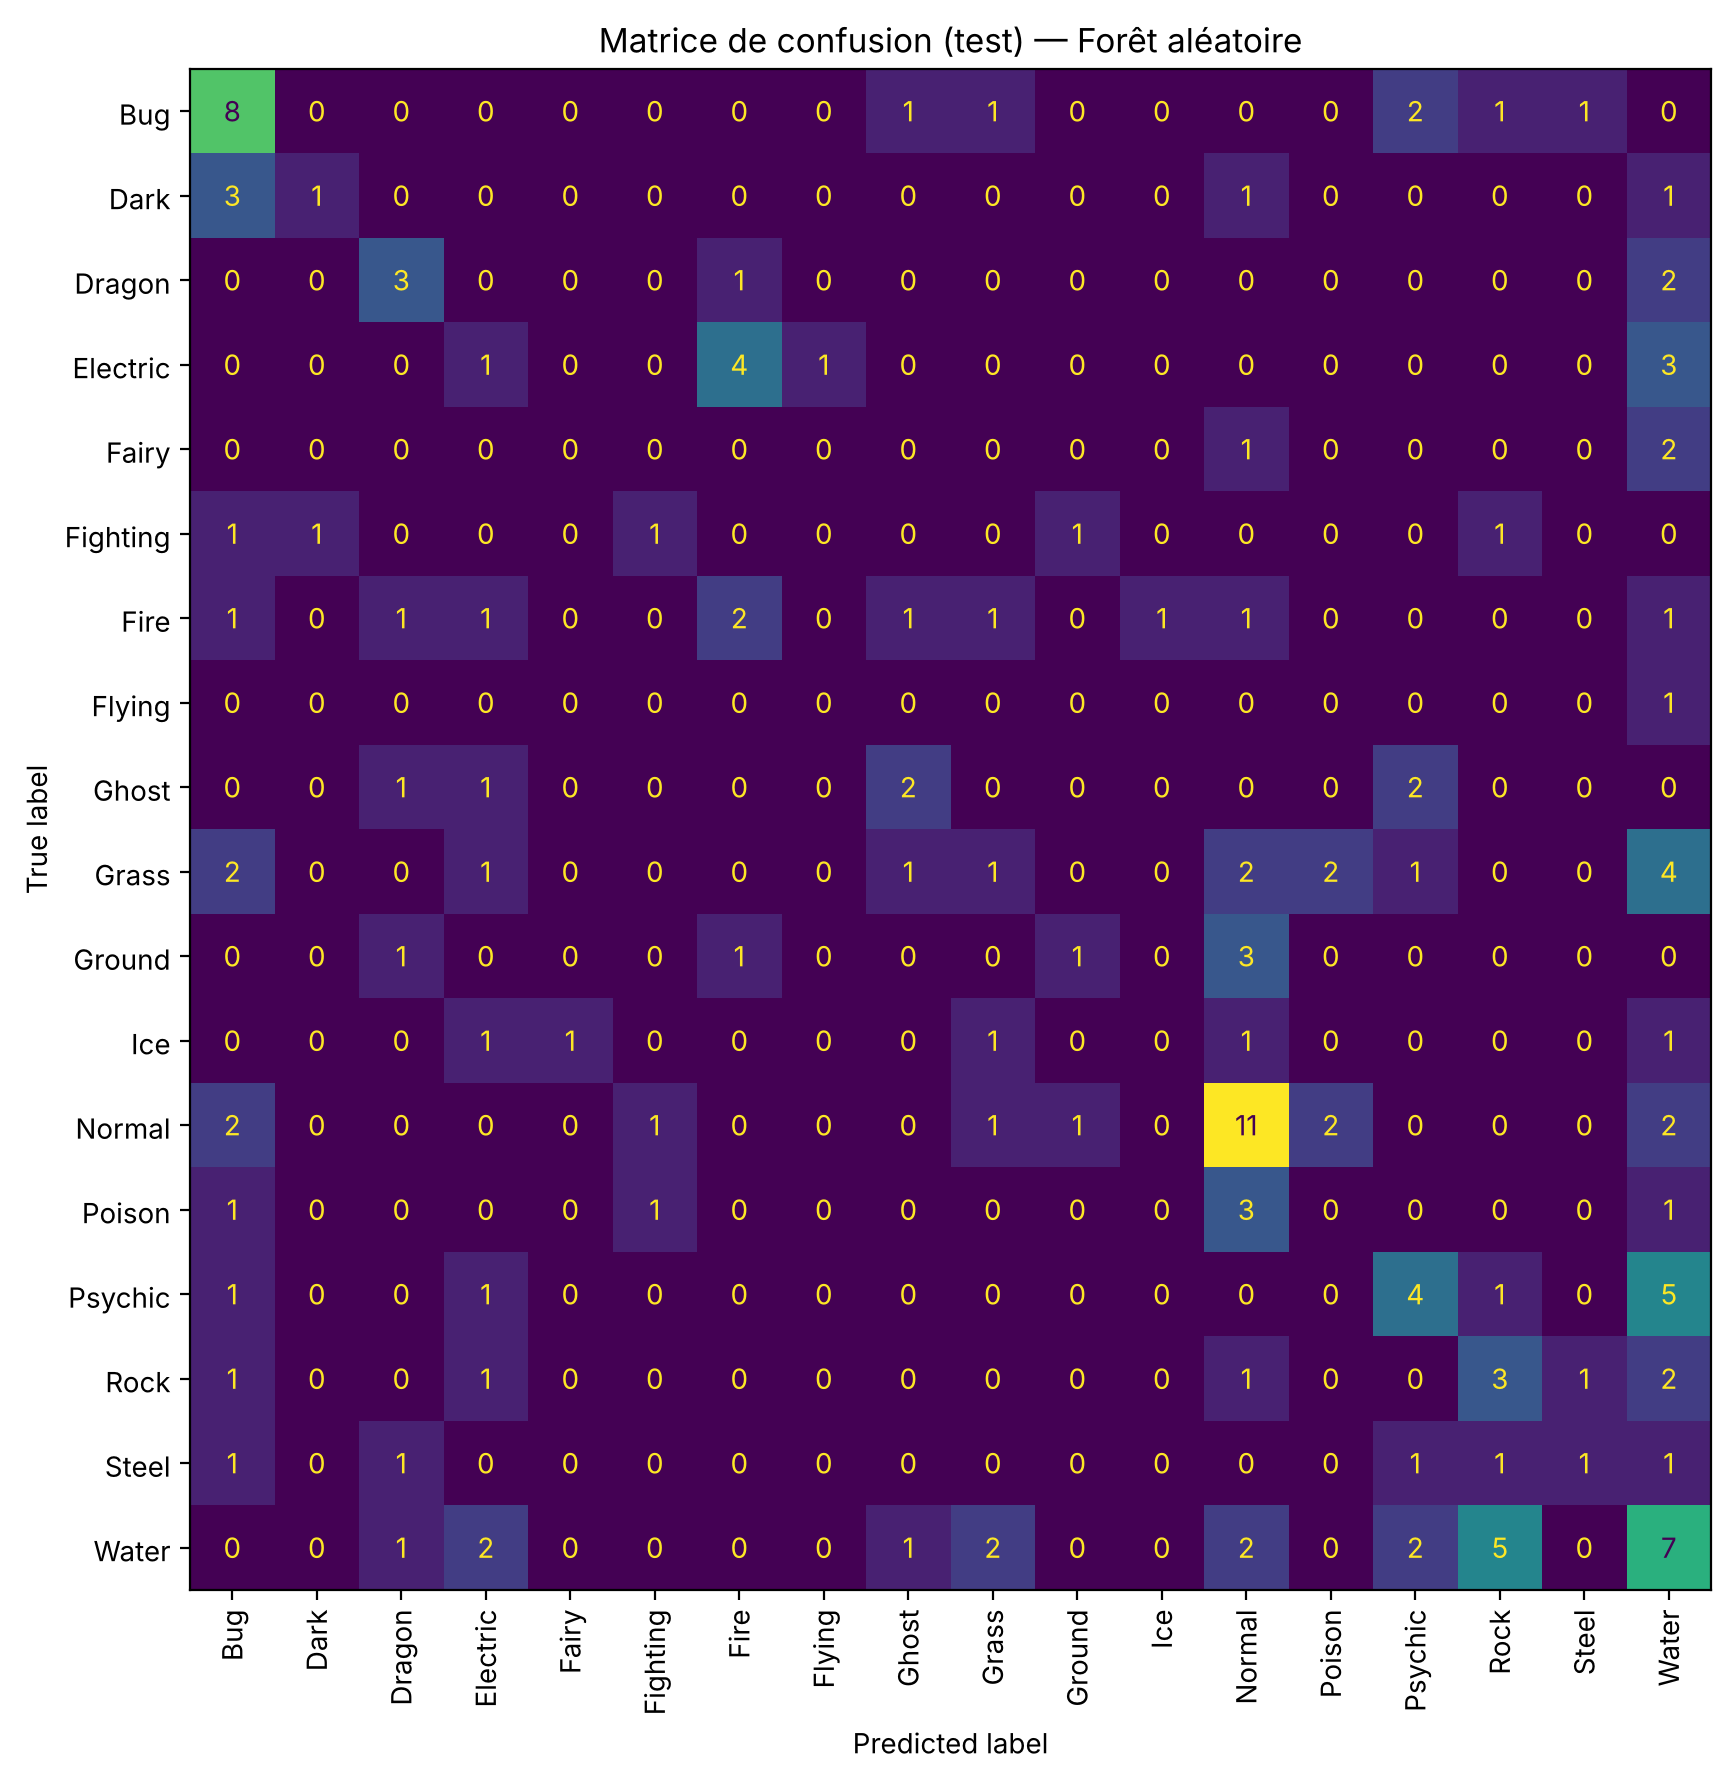

In [13]:
nom_type = pml.MODELE_RETENU["Type 1"]
scores_type, y_test_t, y_pred_t, modele_type = pml.evaluer_sur_test(df, "Type 1", nom_type)
print("Modèle retenu :", nom_type)
print(pd.Series(scores_type).round(3))
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(y_test_t, y_pred_t, ax=ax, xticks_rotation=90, colorbar=False)
plt.title(f"Matrice de confusion (test) — {nom_type}"); plt.tight_layout(); plt.show()

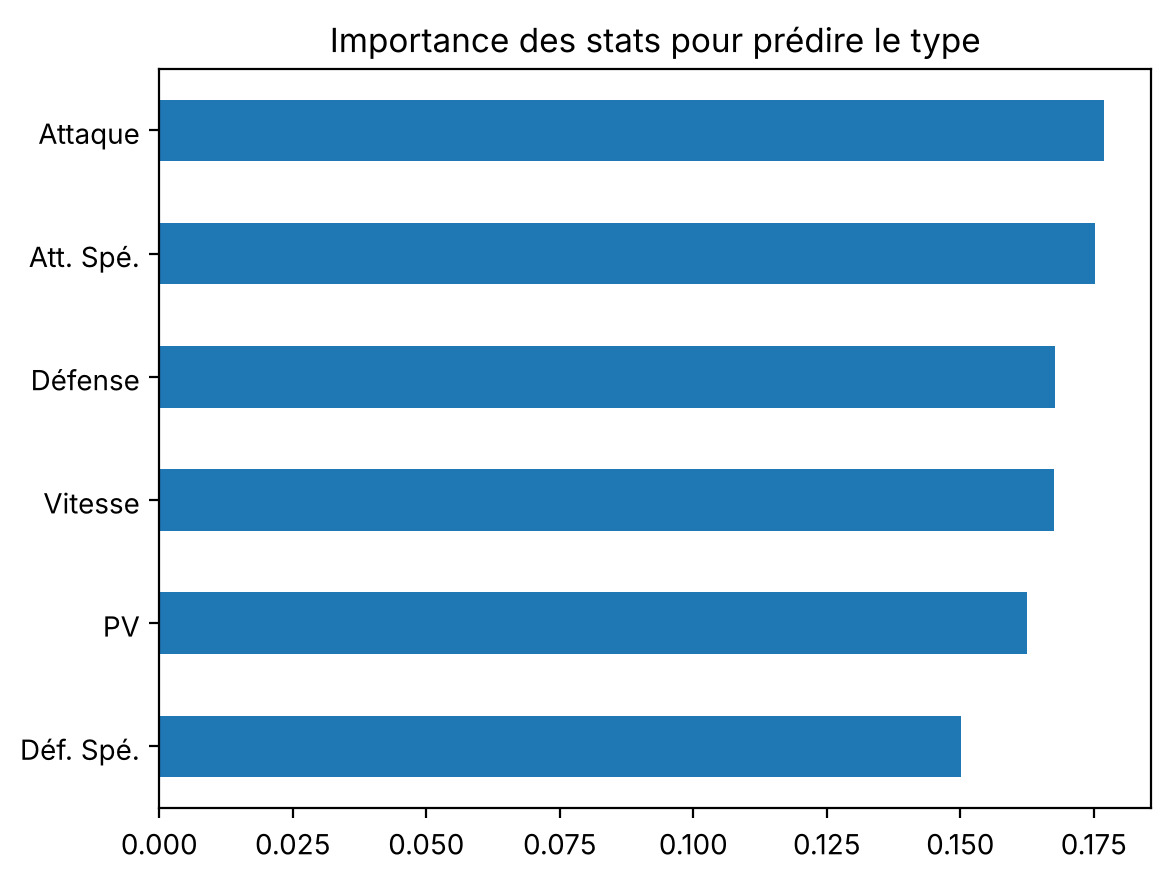

In [14]:
# Importance des stats pour la forêt aléatoire
if nom_type == "Forêt aléatoire":
    imp = pd.Series(modele_type.feature_importances_, index=[pml.STATS_FR[s] for s in pml.STATS])
    imp.sort_values().plot.barh(title="Importance des stats pour prédire le type")
    plt.show()

**Choix** : la **forêt aléatoire** a le meilleur F1 macro. Mais soyons francs : les performances sont
**faibles** (≈ 20-25 % d'accuracy, ~50 % en top-3). C'est attendu : les **stats seules ne déterminent
pas le type** (un Pokémon Eau et un Pokémon Normal peuvent avoir des stats identiques). Seuls quelques
types ont un profil marqué (Acier/Roche = Défense haute, Électrik = Vitesse haute, Psy = Att. Spé. haute).
C'est une vraie **limite du niveau 1**, que le niveau 2 (images) cherche à dépasser.

Pistes d'amélioration : ajouter des features (Génération, Type 2, taille/poids si disponibles),
optimiser les hyperparamètres (GridSearchCV), prédire les deux types (multi-label).

## 5. Utilisation dans l'application

`PokedexIA` ré-entraîne les modèles retenus sur **toutes** les données, puis affiche pour un
Pokémon : son groupe, sa probabilité d'être légendaire et ses 3 types les plus probables.
⚠️ Pour un Pokémon **déjà présent** dans le CSV, la prédiction est trop optimiste (le modèle l'a vu
à l'entraînement) ; l'intérêt est surtout pour des stats **nouvelles**.

In [15]:
ia = pml.PokedexIA(df)
for nom in ["Pikachu", "Mewtwo", "Snorlax"]:
    print(nom, "->", ia.predire(ia.stats_de(nom)))
print("Stats inventées ->", ia.predire([95, 120, 90, 110, 90, 105]))

Pikachu -> {'groupe': 0, 'nom_groupe': 'Faibles (souvent non évolués)', 'exemples_groupe': ['Snorunt', 'Ditto', 'Inkay'], 'proba_legendaire': 1.712455864110905e-05, 'type_predit': 'Electric', 'top3_types': [('Electric', 0.7066666666666667), ('Water', 0.08888888888888889), ('Normal', 0.06666666666666667)]}
Mewtwo -> {'groupe': 2, 'nom_groupe': 'Surpuissants (profil légendaire) – offensifs', 'exemples_groupe': ['Hydreigon', 'Landorus Incarnate Forme', 'Genesect'], 'proba_legendaire': 0.9985677442658951, 'type_predit': 'Psychic', 'top3_types': [('Psychic', 0.6685185185185185), ('Dark', 0.08388888888888889), ('Dragon', 0.07)]}
Snorlax -> {'groupe': 3, 'nom_groupe': 'Intermédiaires – endurants (PV élevés)', 'exemples_groupe': ['Whiscash', 'Swalot', 'Seismitoad'], 'proba_legendaire': 0.07682541381927514, 'type_predit': 'Normal', 'top3_types': [('Normal', 0.6533333333333333), ('Poison', 0.06), ('Water', 0.056666666666666664)]}
Stats inventées -> {'groupe': 2, 'nom_groupe': 'Surpuissants (prof